# Industry Project: "Customers Also Bought" Product Recommender (Production-Style)

> **Who is this notebook for?** Beginners who want to see how recommendation systems are built and evaluated at an online shop, streaming service or app store.
> Every step is explained in plain English and the code is heavily commented.

---

### How this notebook is different from `01_recommendation_systems.ipynb`

| `01_recommendation_systems.ipynb` | This notebook |
|---|---|
| Math of collaborative filtering and matrix factorisation | How a team ships a recommender |
| Explicit star ratings | **Implicit** feedback (clicks/purchases), which is what most companies actually have |
| RMSE on ratings | **Precision@10, Recall@10, coverage**: "did we show the right products?" |

### The business problem
An online store wants a **"Recommended for you"** row on the homepage showing 10 products per user.

Constraints from the product team:
- Don't recommend things the user **already bought**.
- New users with no history (**cold start**) must still see something sensible.
- The recommender must be **better than "just show the best-sellers"**, or it isn't worth maintaining.

### Table of Contents
1. Setup
2. Interaction data (implicit feedback)
3. Build the user-item matrix (sparse!)
4. Time-based split: one global cut-off date
5. Evaluation functions: precision@k, recall@k, NDCG@k, coverage
6. Baseline: most popular items
7. Item-to-item collaborative filtering
8. Matrix factorisation (Truncated SVD)
9. Compare all models
10. Serving: one function with cold-start fallback
11. Summary

---
## 1. Setup

In [1]:
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse                      # sparse matrices: store only the non-zero values
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import normalize

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
K = 10                                        # we recommend 10 items per user

---
## 2. Interaction data (implicit feedback)

Most companies don't have star ratings. They have **events**: *user U viewed/bought item I at time T*.
This is called **implicit feedback**: a purchase suggests interest, but *not* buying doesn't mean dislike (maybe they never saw the item).

We simulate a store with 3,000 users and 600 products in 6 categories. Users have favourite categories, and some products are much more popular than others (the "long tail" seen in every real catalogue).

54,839 purchases | 3,000 users | 600 items


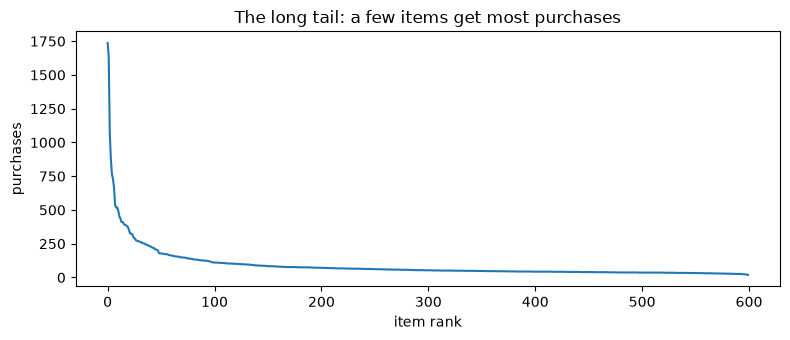

In [2]:
def simulate_interactions(n_users=3000, n_items=600, n_categories=6, seed=RANDOM_STATE) -> tuple:
    rng = np.random.default_rng(seed)
    items = pd.DataFrame({"item_id": np.arange(n_items),
                          "category": rng.integers(0, n_categories, n_items),
                          "popularity": rng.pareto(1.5, n_items) + 1})          # long-tail popularity
    rows = []
    for user in range(n_users):
        favourite = rng.choice(n_categories, size=2, replace=False)           # each user likes 2 categories
        n_events = int(rng.integers(5, 40))
        weights = items["popularity"] * np.where(items["category"].isin(favourite), 8.0, 1.0)
        chosen = rng.choice(n_items, size=n_events, replace=True, p=weights / weights.sum())
        join_day = rng.uniform(0, 170)                                         # users join at different times
        days = np.sort(rng.uniform(join_day, 180, n_events))
        rows += [(user, item, pd.Timestamp("2026-03-01") + pd.Timedelta(days=float(d))) for item, d in zip(chosen, days)]
    events = pd.DataFrame(rows, columns=["user_id", "item_id", "timestamp"])
    return events.drop_duplicates(["user_id", "item_id"], keep="first"), items   # one row per user-item pair


events, items = simulate_interactions()
print(f"{len(events):,} purchases | {events['user_id'].nunique():,} users | {events['item_id'].nunique()} items")

counts = events["item_id"].value_counts().values
plt.figure(figsize=(8, 3.5))
plt.plot(counts)
plt.title("The long tail: a few items get most purchases"); plt.xlabel("item rank"); plt.ylabel("purchases")
plt.tight_layout(); plt.show()

---
## 3. Build the user-item matrix (sparse!)

Rows = users, columns = items, value = 1 if bought.
This matrix is **mostly zeros**: each user bought ~20 of 600 items. Storing all those zeros wastes memory (with millions of users it's impossible), so we use a **sparse matrix** that only stores the 1s.

In [3]:
N_USERS, N_ITEMS = events["user_id"].max() + 1, len(items)


def to_matrix(df: pd.DataFrame) -> sparse.csr_matrix:
    """Turn (user, item) rows into a sparse 0/1 matrix of shape users x items."""
    return sparse.csr_matrix((np.ones(len(df)), (df["user_id"], df["item_id"])), shape=(N_USERS, N_ITEMS))


full_matrix = to_matrix(events)
density = full_matrix.nnz / (N_USERS * N_ITEMS)
print(f"Matrix shape {full_matrix.shape}, filled cells: {density:.2%}")
print(f"Dense storage would be {N_USERS * N_ITEMS * 8 / 1e6:.1f} MB, sparse uses ~{full_matrix.data.nbytes * 3 / 1e6:.2f} MB")

Matrix shape (3000, 600), filled cells: 3.05%
Dense storage would be 14.4 MB, sparse uses ~1.32 MB


---
## 4. Time-based split: one global cut-off date

To test a recommender honestly, we pretend it's the past. We pick **one cut-off date for everybody**: the model trains on everything before it and must **predict what users buy after it**.

Why one date for everyone? If we used a different cut-off per user (e.g. "hide each user's last 20%"), the training data would contain purchases from *after* some users' test periods, so the model could learn future best-sellers. That's the same "peeking into the future" leakage as in fraud detection. (Google's *Rules of ML* #33 recommends exactly this: train on data up to a date, test on data after it.)

Users who appear **only** after the cut-off are **cold-start** users: the model knows nothing about them. We count them separately, because personalised models can't help them (Section 10 handles them).

In [4]:
cutoff = events["timestamp"].min() + pd.Timedelta(days=150)            # ~5 months train, ~1 month test
train_events = events[events["timestamp"] < cutoff]
future_events = events[events["timestamp"] >= cutoff]

known_users = set(train_events["user_id"])
test_events = future_events[future_events["user_id"].isin(known_users)]       # users with some history
cold_start_users = set(future_events["user_id"]) - known_users

train_matrix = to_matrix(train_events)
test_items_per_user = test_events.groupby("user_id")["item_id"].apply(set)    # the "answers"
print(f"Cut-off date: {cutoff.date()}")
print(f"Train purchases: {len(train_events):,} | Future purchases to predict: {len(test_events):,} "
      f"from {len(test_items_per_user):,} known users")
print(f"Cold-start users (first purchase after the cut-off): {len(cold_start_users)}")

Cut-off date: 2026-07-30
Train purchases: 32,687 | Future purchases to predict: 15,225 from 2,518 known users
Cold-start users (first purchase after the cut-off): 380


---
## 5. Evaluation functions: precision@k, recall@k, NDCG@k, coverage

- **Precision@10**: of the 10 items we showed, how many did the user actually buy later?
- **Recall@10**: of the items the user bought later, how many were in our 10?
- **NDCG@10** (Normalised Discounted Cumulative Gain): like precision, but a hit in **position 1** counts more than a hit in position 10, because users mostly look at the first few items. 1.0 = perfect ordering. It's the standard ranking metric in Microsoft's open-source `recommenders` library and in search engines.
- **Catalogue coverage**: what share of all products ever get recommended? A recommender that only ever shows the same 15 best-sellers is bad for business (and boring for users).

In [5]:
def ndcg_at_k(recs: list, truth: set, k: int = K) -> float:
    """Hits near the top are worth more: gain 1/log2(position+1)."""
    dcg = sum(1 / np.log2(pos + 2) for pos, item in enumerate(recs[:k]) if item in truth)
    ideal = sum(1 / np.log2(pos + 2) for pos in range(min(len(truth), k)))   # best possible ordering
    return dcg / ideal


def evaluate(recommend_fn, k: int = K) -> dict:
    """recommend_fn(user_id) -> list of item_ids. Returns ranking metrics over all test users."""
    precisions, recalls, ndcgs, shown = [], [], [], set()
    for user, truth in test_items_per_user.items():
        recs = recommend_fn(user)[:k]
        hits = len(set(recs) & truth)
        precisions.append(hits / k)
        recalls.append(hits / len(truth))
        ndcgs.append(ndcg_at_k(recs, truth, k))
        shown.update(recs)
    return {f"precision@{k}": round(float(np.mean(precisions)), 4),
            f"recall@{k}": round(float(np.mean(recalls)), 4),
            f"ndcg@{k}": round(float(np.mean(ndcgs)), 4),
            "coverage": round(len(shown) / N_ITEMS, 3)}


def remove_already_bought(user: int, scores: np.ndarray) -> np.ndarray:
    """Business rule: never recommend what the user already owns."""
    scores = scores.copy()
    scores[train_matrix[user].indices] = -np.inf
    return scores

---
## 6. Baseline: most popular items
Always start here. In many companies, "best-sellers" is a surprisingly hard baseline to beat.

In [6]:
item_popularity = np.asarray(train_matrix.sum(axis=0)).ravel()     # purchases per item


def recommend_popular(user: int) -> list:
    scores = remove_already_bought(user, item_popularity.astype(float))
    return list(np.argsort(scores)[::-1][:K])


results = {"Most popular": evaluate(recommend_popular)}
results["Most popular"]

{'precision@10': 0.0891,
 'recall@10': 0.1559,
 'ndcg@10': 0.1534,
 'coverage': 0.033}

---
## 7. Item-to-item collaborative filtering

The idea behind Amazon's famous **"customers who bought this also bought..."** (published in 2003 and still widely used):
1. Two items are **similar** if many of the same users bought both (cosine similarity between item columns).
2. A user's score for an item = sum of its similarity to everything the user already bought.

It's simple, explainable ("because you bought X"), and the similarity table can be **pre-computed** overnight.

In [7]:
item_vectors = normalize(train_matrix.T.tocsr(), axis=1)           # each item = vector of its buyers, length 1
item_similarity = (item_vectors @ item_vectors.T).toarray()        # cosine similarity, items x items
np.fill_diagonal(item_similarity, 0)                               # an item shouldn't recommend itself


def recommend_item_cf(user: int) -> list:
    scores = train_matrix[user] @ item_similarity                  # sum of similarities to owned items
    scores = remove_already_bought(user, np.asarray(scores).ravel())
    return list(np.argsort(scores)[::-1][:K])


results["Item-item CF"] = evaluate(recommend_item_cf)
results["Item-item CF"]

{'precision@10': 0.1085,
 'recall@10': 0.1904,
 'ndcg@10': 0.1874,
 'coverage': 0.407}

---
## 8. Matrix factorisation (Truncated SVD)

Matrix factorisation compresses every user and every item into a short list of numbers (e.g. 32), called **embeddings** or **latent factors**. Users and items that "point in the same direction" are a good match.
It captures hidden tastes (e.g. "likes outdoor gear") without anyone defining them.

> **Honest caveat:** plain SVD treats every "not bought" cell as a firm "dislike", which isn't true for implicit data. Production systems use variants designed for implicit feedback, such as **ALS with confidence weights** (`implicit` library), LightFM, or neural two-tower models. SVD is used here because it's built into scikit-learn and shows the idea clearly.

In [8]:
svd = TruncatedSVD(n_components=32, random_state=RANDOM_STATE)
user_factors = svd.fit_transform(train_matrix)          # users x 32
item_factors = svd.components_.T                        # items x 32


def recommend_svd(user: int) -> list:
    scores = user_factors[user] @ item_factors.T        # predicted affinity for every item
    scores = remove_already_bought(user, scores)
    return list(np.argsort(scores)[::-1][:K])


results["Matrix factorisation (SVD)"] = evaluate(recommend_svd)
results["Matrix factorisation (SVD)"]

{'precision@10': 0.0442,
 'recall@10': 0.0757,
 'ndcg@10': 0.0646,
 'coverage': 0.337}

---
## 9. Compare all models

In [9]:
comparison = pd.DataFrame(results).T
lift = comparison[f"precision@{K}"] / comparison.loc["Most popular", f"precision@{K}"]
comparison["lift_vs_popular"] = lift.round(2)
comparison

,precision@10,recall@10,ndcg@10,coverage,lift_vs_popular
Most popular,0.0891,0.1559,0.1534,0.033,1.00
Item-item CF,0.1085,0.1904,0.1874,0.407,1.22
Matrix factorisation (SVD),0.0442,0.0757,0.0646,0.337,0.50


**How to read this:**
- **Lift > 1** means the model beats best-sellers. A lift of 2.0 means twice as many relevant products shown.
- **Item-item CF wins** on every metric here. **Plain SVD loses to best-sellers.** This happens a lot in real projects, and it's exactly why you always build the popularity baseline first. SVD ignores how popular items are and treats "not bought" as "disliked", so a fancier model is not automatically a better one. Implicit-feedback methods (ALS, two-tower models) usually fix this.
- **Coverage**: personalised models recommend a much wider part of the catalogue, which helps sell long-tail products.
- In a company, the offline winner then goes to an **A/B test** with real users (see `../11_ab_testing/01_ab_testing.ipynb`) before full launch, because offline metrics don't always match real behaviour.

---
## 10. Serving: one function with cold-start fallback

The production function has to handle every type of user:
- **known user** → personalised recommendations,
- **brand-new user** (no history) → popular items (optionally filtered by the category they're browsing).

It also returns **explanations** ("Because you bought ..."), which increases click-through in practice.

In [10]:
def get_recommendations(user_id: int | None, k: int = K, browsing_category: int | None = None) -> dict:
    """What the homepage API would call."""
    known_user = user_id is not None and user_id < N_USERS and train_matrix[user_id].nnz > 0
    if not known_user:                                                  # COLD START
        scores = item_popularity.astype(float).copy()
        if browsing_category is not None:
            scores[items["category"].values != browsing_category] = -np.inf
        top = np.argsort(scores)[::-1][:k]
        return {"strategy": "popular (cold start)", "items": [int(i) for i in top]}

    top = recommend_item_cf(user_id)[:k]
    owned = train_matrix[user_id].indices
    explanations = {}
    for item in top[:3]:                                                # explain the first 3
        because = owned[np.argmax(item_similarity[item, owned])]        # most similar owned item
        explanations[int(item)] = f"Because you bought item {int(because)}"
    return {"strategy": "item-item CF", "items": [int(i) for i in top], "explanations": explanations}


some_known_user = int(test_items_per_user.index[0])                          # a user with purchase history
print(get_recommendations(user_id=some_known_user))
some_new_user = sorted(cold_start_users)[0] if cold_start_users else None
print(get_recommendations(user_id=some_new_user, browsing_category=2))       # a real cold-start user

{'strategy': 'item-item CF', 'items': [583, 405, 81, 121, 312, 309, 216, 50, 395, 279], 'explanations': {583: 'Because you bought item 531', 405: 'Because you bought item 531', 81: 'Because you bought item 531'}}
{'strategy': 'popular (cold start)', 'items': [81, 267, 90, 378, 266, 93, 434, 551, 67, 300]}


---
## 11. Summary

| Industry practice | What we did |
|---|---|
| Implicit feedback | Purchases instead of ratings |
| Sparse data structures | `scipy.sparse` user-item matrix |
| Honest evaluation | One global time cut-off, cold-start users counted separately |
| Ranking metrics | precision@k, recall@k, NDCG@k, catalogue coverage |
| Strong baseline | Most-popular items |
| Business rules | Filter already-bought items |
| Explainability | "Because you bought X" |
| Robust serving | Cold-start fallback |

### Practice exercises
1. Change `n_components` in the SVD to 8 and 128. What happens to precision, NDCG and coverage?
2. Blend the two models: `0.5 * item_cf_score + 0.5 * svd_score` (normalise first!).
3. Add a "diversity" rule: at most 4 items from the same category in the top 10.

### Resources
- Microsoft `recommenders` repo (algorithms + evaluation utilities): https://github.com/recommenders-team/recommenders
- Linden, Smith & York (2003), *Amazon.com Recommendations: Item-to-Item Collaborative Filtering*

### Related notebooks
- Theory: `01_recommendation_systems.ipynb`
- Ranking models: `../01_supervised/12_learning_to_rank.ipynb`
- Approximate nearest neighbours for large catalogues: `../../13_Databases/03_vector_db/01_vector_databases.ipynb`